# Pycavi illumination correction via Kriging

This notebook is used to determine the illumination correction, an effect that can
imprint systematic variations above 0.2 mags accross the field for wide field
imagers such as OmegaCam and WFI. Pycavi offers two ways to determine the illumination correction.
Here we use the Kriging method.

**Kriging**, not as well known, but very powerful as it permits the best unbiased estimator when we interpolate data between points. The disadvantage of Krigging is that it could usse all stars in the fields to carry out the calculations, depending on the correlations of the data, this last one is given by the variogram. For filters such as NB_659 Krigging gives an advantage over Chebyshev as it takes better care of short range correlation. In the case of OmegaCam NB_659, using kriging one *rediscovers* the four quadrants of the filter.
  - *Variogram*. When kriging the first step is to determine the variogram, a 1d function that gives the correlations of the data-values as a function of distance. This function starts at zero with a value called the *nugget*, and increases up to a maximum after which should remains flat. Except that it does not due to edge and other effects. The value of distance where the variogram flattens, the *range*, indicates the point at which the data is not correlated anymore. The two other parameters of kriging are the *sill*, which is the value of the variogram at the flat part, and the *partial sill*, which is the difference between the sill and the nugget. The user can play with a few parameters:
    - maxlag: maximum distance between two points that will be used in the modeling of the variogram, typically approx. half the image size,
    - nlags:  number of bins between 0 and maxlag, tipically 200 - 500.
    - nugget: smallest value of the correlation at short distances. When the residuals are noisy this number will be larger as it gives the short scale variance of the data (random errors of the photometry).
  The *nugget* gives the value of the short scale variance of the data. After the variogram is determined we fit one of the approximation functions: gaussian, exponential, or spherical. Sometimes the value of the nugget determined by the fit to the variogram is allways too small compared to what we could extrapolate to 0-lag from the data. This typically occurs when the fitting function is not a very good approximation to the variogram. The notebook offers the possibility of fixing this value when doing the fit, as having a meaningfull nugget ensure that noisy data is not overfitted.
  
  Afer this we use the UniversalKriging function of the python package pykrige to do the actual determination of covariances which are used for interpolation.

**Determination of uncertainties**. The error determination when kriging is a delicate because the interpolation is exact for the points used for the interpolation. We offer two possible paths: (1) use the same points used for the kriging interpolation determination, but with a small adjustable offset, dpix. This is the quick way that should be used for a first run until the best kriging parameters are determined. Once the user is happy with the parameters, then the k-fold method can be selected where a (100-k)% of points are used for interpolation, and the remaianing k% are used to determine residuals. This means that roof(100/k) number of iterations will need to be performed.

At this point the illumination correction is shown as a colour image with contours overlaid.
The image is saved to a file with root name equal to the image root name in the Calibration directory.

  - After the illumination correction determination the photometry is corrected and the
residuals are ploted for both the corrected magnitudes and the raw magnitudes. Two plots
are generated for QC purposes: a residuals versus x-coordinates for the uncorrected points
in red, and the corrected points in black; and a histogram of the residuals for both
sets of points. The mean, median and 1-sigma variation is reported in these plots.
The plots are saved with the root-name of the image plus a string giving the type
of correction and the string _res_01.png at the end.

  - Another set of plots is presented with the residuals as a function of radius, azimuthal
angle measured from the center of the FoV, and versus x and y. These plots have similar names
as the previous set, but with end string _res_02.png.



In [1]:
import os
import sys
import glob
import copy
import logging

import numpy as np
from numpy.polynomial import chebyshev
import pandas as pd

#import matplotlib.pyplot as plt
#import matplotlib.gridspec as gridspec
#from matplotlib import cm
#from mpl_toolkits.axes_grid1 import make_axes_locatable

from astropy.stats import sigma_clipped_stats, sigma_clip
from astropy.visualization import simple_norm
from astropy.coordinates import SkyCoord
from astropy import units as u
from astropy.io import fits
from astropy.wcs import WCS

from scipy.interpolate import griddata, Rbf
from scipy.stats import norm

from photutils.aperture import SkyCircularAperture, SkyCircularAnnulus, aperture_photometry


#   from pycavi_astromatic import SExtractor
sys.path.append(os.path.join(os.path.abspath(''), '..')) # to be removed in production

from pycavi import pycavi_tools
from pycavi.pycavi_zpcal import extract_calibration, plot_zpcal, get_files_dict, save_illumination_data, read_illumination_data
from pycavi.pycavi_zpcal import plot_residuals, plot_illumination_correction, plot_corrected_residuals, plot_spatial_residuals
from pycavi.pycavi_kriging import kriging_interpolation, determine_kriging_errors, save_kriging_model, get_kriging_interpolation


This will be executed when the package is imported.


In [2]:
# set the directory folders
config_dir = os.getcwd()+'/../config/'
config = pycavi_tools.read_pycavi_config(config_dir)

observatory = config['Provenance']['observatory'] # Needed for the atmospheric extinction curve
project_dir = config['Directories']['project_dir']
reduced_std_dir = config['Directories']['reduced_std_dir']
reduced_science_dir = config['Directories']['reduced_science_dir']  
log_dir = config['Directories']['project_logs_dir']

log_file_swarp = log_dir + "/pymeffpp_zpcal_check.log"
logging.basicConfig(level=logging.INFO,
                    format="%(asctime)s:%(levelname)s:%(message)s",
                    handlers=[
                              logging.FileHandler(log_file_swarp),
                              logging.StreamHandler()])
logging.getLogger().setLevel(logging.INFO)

# At this point it is believed that the data reduction process
# should be closely monitored, so we calibrate target/filter sets,
# that is each data partition, one by one.
#
filters = []
reject_observations = []
dir_name = config['Directories']['cal_dir_name']
zpcal_dict = get_files_dict(reduced_std_dir, reduced_science_dir, dir_name, filters, reject_observations)

observation_tags = list(set(zpcal_dict.keys()))
observation_tags.sort()    # Needed to ensure same index in every run
illum_files = []
for i in range(len(observation_tags)):
    logging.debug("index: {} observation_tag: {}".format(i, observation_tags[i]))
    for j in range(len(zpcal_dict[observation_tags[i]])):
        directory = os.path.dirname(zpcal_dict[observation_tags[i]][j])
        file_name_noext = os.path.splitext(os.path.basename(zpcal_dict[observation_tags[i]][j]))[0]
        illum_file = os.path.join(directory, file_name_noext)+ '.illum.csv'
        if os.path.isfile(illum_file):
            illum_files.append(illum_file)

for i in range(len(illum_files)):
    logging.info("index: {} -- illum: {}".format(i, illum_files[i]))



2024-11-06 15:48:28,984:INFO:index: 0 -- illum: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_NB_659.coadd.illum.csv
2024-11-06 15:48:28,985:INFO:index: 1 -- illum: /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_r_SDSS.coadd.illum.csv


In [3]:
# Here we loop over the selected csv files output of notebook 07b_pycavi_zpcal_qc
# See list above to select a data partition to calibrate
# For example, if the list is:
#
# index: 0 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/CP_Pup/Calibration_dir/CP_Pup_r_SDSS.coadd.csv
# index: 1 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Calibration_dir/M67_g_SDSS.coadd.csv
# index: 2 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Calibration_dir/M67_r_SDSS.coadd.csv
# index: 3 -- file: /Users/fselman/Pictures/OCAM/MultiObject/science/M67/Calibration_dir/M67_NB_659.coadd.csv
# index: 4 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA101/Calibration_dir/SA101_g_SDSS.coadd.csv
# index: 5 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA101/Calibration_dir/SA101_r_SDSS.coadd.csv
# index: 6 -- file: /Users/fselman/Pictures/OCAM/MultiObject/std/SA98/Calibration_dir/SA98_NB_659.coadd.csv
#
# then to calibrate M67_NB_659.coadd.csv set
#
# idx_selected = [3]
#

idx_selected = [0]    # Keep empty to check all files
for i in range(len(illum_files)):
    
    # skip indices not in list idx_selected
    if not (i in idx_selected or not idx_selected):
        continue

    # For checking we read it again and continue with plotting
    headers, data_df = read_illumination_data(illum_files[i])
    #display(data_df)
    print(data_df.columns)

    x_all = data_df['x_all'].to_numpy()
    y_all = data_df['y_all'].to_numpy()
    z_all = data_df['z_all'].to_numpy()
    z_all_err = data_df['z_all_err'].to_numpy()
    mag_std = data_df['mag_std'].to_numpy()

    dimx = int(headers['dimx'])
    dimy = int(headers['dimy'])
    origfile = headers['origfile']
    image_dir = headers['image_dir']
    image_name = headers['image_name']
    image_path = headers['image_path']
    band = headers['band']
    logging.info(f"image_name: {image_name}")
    
    brightest_mag = 12.0
    faintest_mag = 16.0
    dm_min = -0.25
    dm_max = 0.25

    z_all_clipped = sigma_clip(z_all, sigma=3.0, maxiters=5)
    mask = ~np.isnan(z_all) & ~z_all_clipped.mask & np.isfinite(z_all) & \
        (brightest_mag < mag_std) & (mag_std < faintest_mag) & \
        (dm_min < z_all) & (z_all < dm_max)
    x_subset = x_all[mask]
    y_subset = y_all[mask]
    z_subset = z_all[mask]
    z_subset_err = z_all_err[mask]

    z_mean_u, z_median_u, z_std_u = sigma_clipped_stats(z_subset, sigma=3.0, maxiters=5)
    logging.info("mean: {}  --  median: {}  --  stdev: {}".format(round(z_mean_u, 4), round(z_median_u, 4), round(z_std_u, 4)))

    n_before_filter = len(x_all)
    n_after_filter = len(x_subset)
    logging.info("Filtering: number of data points {} ---> {} ({} {})".format(n_before_filter, n_after_filter, dimx, dimy))
        

    
logging.info("-------Done-------")

2024-11-06 15:48:36,923:INFO:image_name: CP_Pup_NB_659.coadd
2024-11-06 15:48:36,926:WARNING:Input data contains invalid values (NaNs or infs), which were automatically clipped.
2024-11-06 15:48:36,928:INFO:mean: -0.0097  --  median: -0.006  --  stdev: 0.0563
2024-11-06 15:48:36,928:INFO:Filtering: number of data points 3661 ---> 2391 (19119 19987)
2024-11-06 15:48:36,929:INFO:-------Done-------


Index(['x_all', 'y_all', 'mag_std', 'mag_frame', 'z_all', 'z_all_err'], dtype='object')


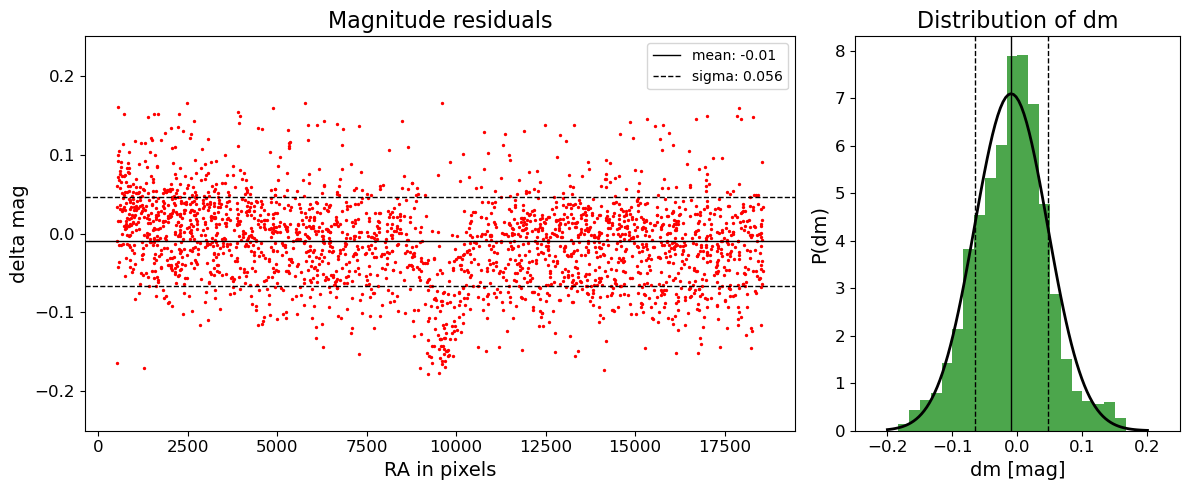

In [4]:
############################ 03 PLOT RESIDUALS AND PDF FOR UNCORRECTED DATA ####################
#
plot_residuals(x_subset, z_subset, ylim=(-0.25, 0.25))

2024-11-06 15:54:08,407:INFO:number of points for krigging: 2391
2024-11-06 15:54:09,636:INFO:Saving variogram in /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_NB_659.coadd_variogram_gaussian_200_8000_0.00249.png


edists.shape: (2857245,)  elags.shape: (199,)  esemivariance.shape: (199,)
{'psill': 0.001050814447547362, 'range': 4410.352884555241, 'nugget': 0.0024888505344721826}
Fitted Nugget: 0.0024888505344721826, Partial Sill: 0.001050814447547362, Range: 4410.352884555241


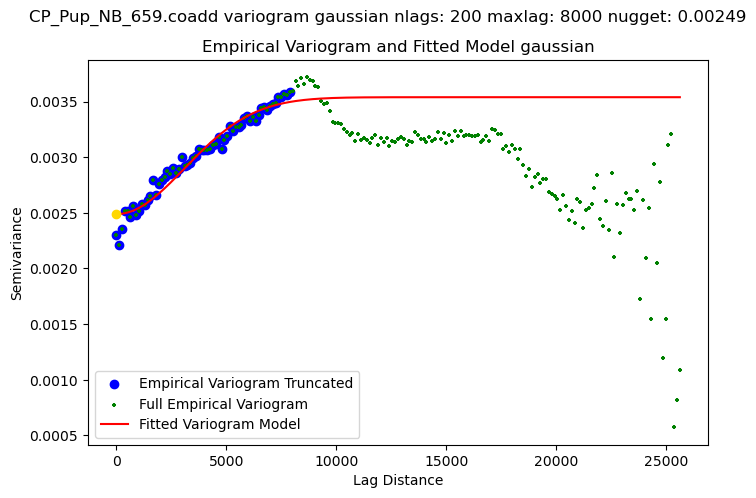

Adjusting data for anisotropy...
Initializing variogram model...
Using 'gaussian' Variogram Model
Partial Sill: 0.001050814447547362
Full Sill: 0.0035396649820195443
Range: 4410.352884555241
Nugget: 0.0024888505344721826 

Calculating statistics on variogram model fit...
Q1 = 0.01965838768159454
Q2 = 0.9873505540413129
cR = 0.002657593388197143 

Initializing drift terms...
Executing Universal Kriging...



2024-11-06 15:56:23,716:INFO:mean: -0.0015  --  median: 0.0013  --  stdev: 0.046


Executing Universal Kriging...



2024-11-06 15:56:24,649:INFO:######################### DONE ######################


grid_z.shape: (50, 50) --  grid_x.shape: (50, 50)


In [10]:
# Here we fit the data either with Chebyshev or kriging method
# Play with the degree until the sigma of residuals is minimal.
# Typically deg of 4 to 7.


#################################### 04 FIT RESIDUAL DATA ###############################
#
# Perform Universal Kriging interpolation
# This is a very expensive process. Data needs to be filtered out.
# O(N^3+MxN^2) where N: sample data points, M: number of grid points
#
# It is important to run this notebook cell by parts:
#
#   - Determine best variogram fit and nugget:
#
#.      - Start with maxlag qual to half the size of the FoV, nlags 200, fit_type lmfit, nugget None.
#.          -> inspect the plot of the variogram to decide whether to change the model, maxlag
#           -> once you have the best model and maxlag (the variogram should rise for the fitted nugget
#            then level off a the sill at around maxlag
#
   
logging.info(f"number of points for krigging: {len(x_subset)}")

# set Kriging parameters
maxlag = 8000
nlags = 200
selected_model = 'gaussian'        # exponential, gaussian, or spherical
init_kriging = False                # Use a call to uk to determine parameters    
use_empirical_variogram = True
determine_empirical_variogram = True
fit_type = 'lmfit'                 # curve_fit or lm_fit. Fixing nugget must use lmfit
fixed_nugget = None                # if fit type is lmfit you can set this number, otherwise leave it at None
save_kriging_grid = True          # Once user is happy with the results change this to True for a final run

# Define some strings for the plots and the FITS file to save the kriging parameters
fit_image_title = f"{image_name}: kriging {selected_model}\n nlags: {nlags} maxlag: {maxlag} interp. to residuals"
if fixed_nugget is None:
    fit_plot = image_path+"_krige_"+selected_model+"_nugget"+"_fit_01.png"
    krige_fits_name = image_path+"_krige_"+selected_model+"_nugget"+"_fit_01.kriging.fits"
    res_plot_str = image_path+'_krige_'+selected_model+"_nugget"+"_res"
else:
    fit_plot = image_path+"_krige_"+selected_model+f"_fixed{fixed_nugget}"+"_fit_01.png"
    krige_fits_name = image_path+"_krige_"+selected_model+f"_fixed{fixed_nugget}"+"_fit_01.kriging.fits"
    res_plot_str = image_path+'_krige_'+selected_model+f"_fixed{fixed_nugget}"+"_res"

# we determine best interpolation using all points
plot_variogram = True
UK = kriging_interpolation(x_subset, y_subset, z_subset, 
                    init_kriging = init_kriging, 
                    selected_model = selected_model, 
                    maxlag = maxlag, 
                    nlags = nlags, 
                    determine_empirical_variogram = determine_empirical_variogram, 
                    plot_variogram = plot_variogram,
                    use_empirical_variogram = use_empirical_variogram,
                    fit_type = fit_type,
                    fixed_nugget = fixed_nugget,
                    image_path=image_path)

# We do 100/A runs to determine kriging errors
# k-fold cross-validation procedure using k% of points at a time for each determination
# until all points have been used.
#
determine_errors = True
use_kfold = False
if determine_errors is True:
    if use_kfold:     # this is the proper way but it is slow. In a first pass set use_kfold to False
        k = 25        # should be small enough not to affect quality of estimation, but the smaller the costier
        x_check, y_check, z_check, z_corr = determine_kriging_errors(x_subset, y_subset, z_subset, 
                                         k=k,
                                         init_kriging=init_kriging, 
                                         selected_model=selected_model, 
                                         maxlag=maxlag, 
                                         nlags=nlags, 
                                         determine_empirical_variogram=determine_empirical_variogram, 
                                         plot_variogram=plot_variogram, 
                                         use_empirical_variogram=use_empirical_variogram,
                                         fit_type = fit_type,
                                         fixed_nugget = fixed_nugget)
        print("z_corr.shape: {}".format(z_corr.shape))
        err_type = f"err_kfold{k}"

        z_mean, z_median, z_std = sigma_clipped_stats(z_corr, sigma=3, maxiters=5)
        logging.info("mean: {}  --  median: {}  --  stdev: {}".format(round(z_mean, 4), round(z_median, 4), round(z_std, 4)))
    else:
        x_check = x_subset
        y_check = y_subset
        z_check = z_subset
        dpix = 4
        corr, _ = UK.execute('points', x_check+dpix, y_check+dpix)    # we offset a little otherwise corrections would be zero
        z_corr = z_check - corr
        err_type = "err_simple"

        z_mean, z_median, z_std = sigma_clipped_stats(z_corr, sigma=3, maxiters=5)
        logging.info("mean: {}  --  median: {}  --  stdev: {}".format(round(z_mean, 4), round(z_median, 4), round(z_std, 4)))
else:
    x_check = x_subset
    y_check = y_subset
    z_check = z_subset
    dpix = 4
    corr, _ = UK.execute('points', x_check+dpix, y_check+dpix)
    err_type = 'err_none'
    z_corr = z_check - corr

    z_mean, z_median, z_std = sigma_clipped_stats(z_corr, sigma=3, maxiters=5)
    logging.info("mean: {}  --  median: {}  --  stdev: {}".format(round(z_mean, 4), round(z_median, 4), round(z_std, 4)))

# Names for residual plots
save_res_plot_01 = res_plot_str+"_"+err_type+"_01.png"
save_res_plot_02 = res_plot_str+"_"+err_type+"_02.png"

# Interpolate onto the grid
# Here I add new code
# Define the grid size
n_pts = 50
gridx = np.linspace(1, dimx, n_pts)
gridy = np.linspace(1, dimy, n_pts)

# we get the values and the variances
grid_z, ss = UK.execute('grid', gridx, gridy)

# we create an image
grid_x, grid_y = np.meshgrid(gridx, gridy)
print("grid_z.shape: {} --  grid_x.shape: {}".format(grid_z.shape, grid_x.shape))

# Here we save the kriging interpolation grid to a FITS file
#
# original_height = header['ORIG_H']
# original_width = header['ORIG_W']
# factor = header['FACTOR']
# variogram_model = header['VARIOMOD']

# If Kriging parameters are included in the header
# nugget = header.get('NUGGET', None)  # Use None if not present
# sill = header.get('SILL', None)
# range_val = header.get('RANGE', None)

header_dict = {}
header_dict['IMGNAME'] = (image_name, 'Name of image for the correction')
header_dict['IMGORIG'] = (origfile, 'Original file name for the correction')
header_dict['BAND'] = (band, 'Photometric band of the image')
header_dict['BRIGTMAG'] = (brightest_mag, 'Brightest star used for filtering')
header_dict['FAINTMAG'] = (faintest_mag, 'Faintest star used for filtering')
header_dict['DMMIN'] = (dm_min, 'Min magnitude difference')
header_dict['DMMAX'] = (dm_max, 'Max magnitude difference')
header_dict['MAXLAG'] = (maxlag, 'Max lag used for variogram fit')
header_dict['NLAGS'] = (nlags, 'Number of lags for variogram histogram')
if 'kfold' in err_type:
    header_dict['ERRTYPE'] = (err_type, f'Method used to determine std-dev. k= {k}')
else:
    header_dict['ERRTYPE'] = (err_type, 'Method used to determine std-dev')
header_dict['ORIG_H'] = (dimy, 'y-dimension of original image')
header_dict['ORIG_W'] = (dimx, 'x-dimension of original image')
header_dict['FACTOR'] = (n_pts, 'Factor for the grid subsample')
header_dict['VARIOMOD'] = (selected_model, 'Function use to model variogram')
header_dict['FITTYPE'] = (fit_type, 'Python fiting procedure')
uk_psill, uk_range, uk_nugget = UK.variogram_model_parameters
header_dict['NUGGET'] = (round(uk_nugget, 6), 'Nugget value of best fit model')
header_dict['PSILL'] = (round(uk_psill, 6), 'Partial sill of best fit model')             # we always use PSILL in procedure kriging_interpolation()
header_dict['RANGE'] = (round(uk_range, 1), 'Range of best fit model')
header_dict['ZMEANU'] = (round(z_mean_u, 6) , 'mean of uncorrected mag diffs')
header_dict['ZMEDIANU'] = (round(z_median_u, 6), 'median of uncorrected mag diffs') 
header_dict['ZSTDU'] = (round(z_std_u, 4), 'std-dev  of uncorrected mag diffs')
header_dict['ZMEANC'] = (round(z_mean, 6),  'mean of corrected mag diffs')
header_dict['ZMEDIANC'] = (round(z_median, 6), 'median of corrected mag diffs')  
header_dict['ZSTDC'] = (round(z_std, 4), 'std-dev  of corrected mag diffs')  



logging.info("######################### DONE ######################")


In [12]:
if save_kriging_grid:
    save_kriging_model(grid_z, n_pts,  header_dict, krige_fits_name)
    

2024-11-06 15:56:35,855:WARNING:VerifyWarning: Card is too long, comment will be truncated.


2024-11-06 15:56:31,662:INFO:Saving fit plot to /home/lceledon/Investigacion/OmegaCam/Work_dir//science/CP_Pup/Calibration_dir/CP_Pup_NB_659.coadd_krige_gaussian_nugget_fit_01.png


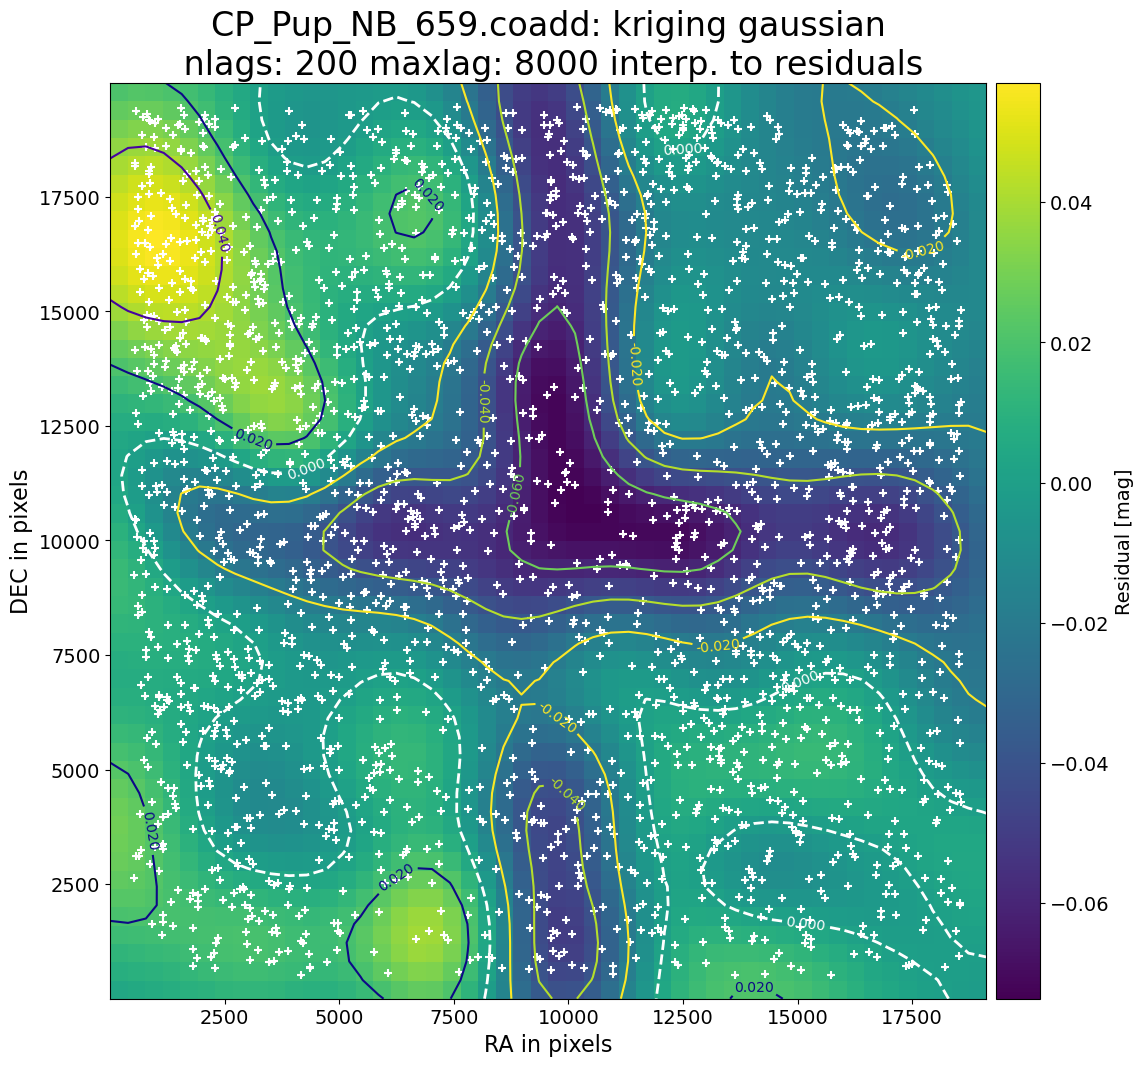

In [11]:
########################################## 05 PLOT APPROXIMATING SURFACE ###########################
#
plot_illumination_correction(x_subset, y_subset, x_check, y_check, grid_x, grid_y, grid_z, dimx, dimy, fit_plot, fit_image_title)

2024-11-06 15:56:39,275:INFO:subset mean: -0.0097  --  median: -0.006  --  stdev: 0.0563
2024-11-06 15:56:39,278:INFO:corrected mean: -0.0015  --  median: 0.0013  --  stdev: 0.046
2024-11-06 15:56:39,390:INFO:Saving residual plots to None


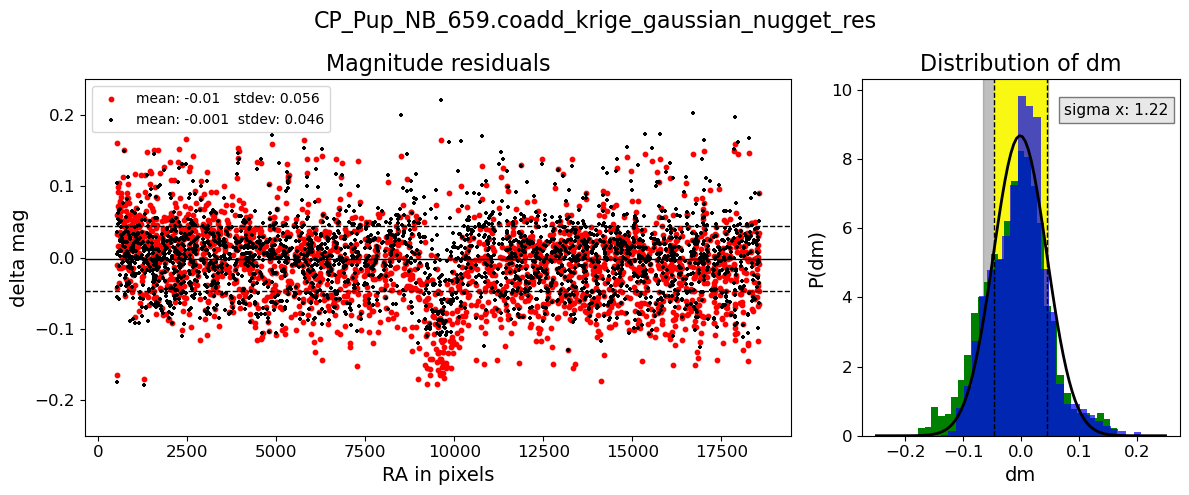

In [13]:
######################### PLOT RESIDUALS AND RMS ESTIMATE USING INDEPENDENT DATA POINTS ##################
#
#image_path = zpcal.image_path[:-5]
#image_name = image_name.split("/")[-1]

# In cases where edge oscilations are large  we might need to clip
# the max and minimum values.
min_corr = -0.20
max_corr = 0.25
#z_corr = np.clip(z_corr, min_corr, max_corr)
save_res_plot_01 = res_plot_str+"_"+err_type+"_01.png"
plot_corrected_residuals(x_subset, z_subset, x_check, z_corr, res_plot_str, determine_errors, err_type, ylim=(-0.25, 0.25), save_plot=None)

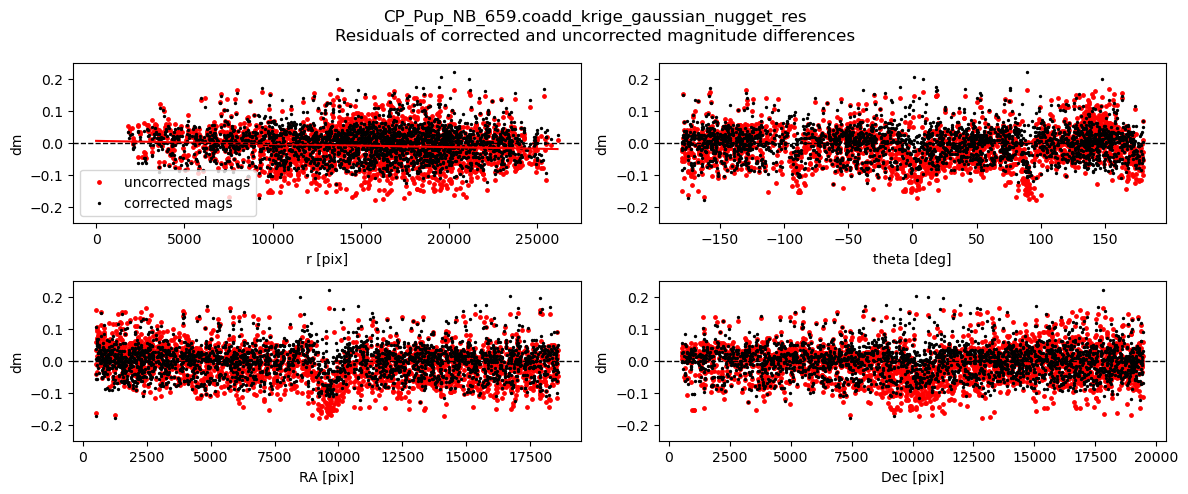

In [14]:
############################ EXTENSIVE SPATIAL PLOTS OF RESIDUALS ###########################
#    
plot_spatial_residuals(x_subset, y_subset, z_subset, x_check, y_check, z_corr, dimx, dimy, res_plot_str, err_type, ylim=(-0.25, 0.25))

### 